# Using Multiple Layers

*Section 2 — Making maps, notebook 4 of 4.* Previous: `03_maps_from_vector_data.ipynb`. Next: `03_vector_data_and_zonal_stats/01_zonal_statistics.ipynb`.

**You will learn:**
- how to check and match the projections of raster and vector layers before mapping them together;
- how to overlay vector layers on a satellite image, side by side with the image alone (`create_map_panels`);
- how to make a choropleth map (features coloured by an attribute) with a colour bar, using the collection the map function returns;
- how to build a multi-panel figure with zoomed-in maps and their extents drawn on an overview map.

**Before you start:** the image and vector maps from `02_maps_from_eo_data.ipynb` and `03_maps_from_vector_data.ipynb`.

**Data:** `../data/gmw/gmw_loss_alerts_utm.geojson` (Global Mangrove Watch loss alerts), `../data/gmw/gmw_2018_ext_alerts.geojson` (GMW 2018 mangrove extent) and `../data/gmw/landsat_2023_gmw_alerts.tif` (Landsat 2023 image), for a region of Guinea-Bissau.

**Run time:** less than 1 minute.

It is common that we want to create our maps from mutliple layers, both raster and vector and therefore this notebook will show an example of doing that for a set of Global Mangrove Watch loss alerts for a region in Guinea-Bissau.

## Load Modules

In [1]:
%matplotlib inline
import os

import geopandas
import matplotlib
import matplotlib.colors
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import rsgispy
import rsgispy.imageutils.metadata
import rsgispy.mapping.elements
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster
import rsgispy.mapping.vector

# The figures saved by this notebook are written to the outputs directory
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

## Specify File Paths

In [2]:
vec_alerts_file = "../data/gmw/gmw_loss_alerts_utm.geojson"
vec_gmw_ext_file = "../data/gmw/gmw_2018_ext_alerts.geojson"
landsat_img = "../data/gmw/landsat_2023_gmw_alerts.tif"

## Loads Vector Data

In [3]:
gmw_alerts_gdf = geopandas.read_file(vec_alerts_file)
gmw_2018_ext_gdf = geopandas.read_file(vec_gmw_ext_file)

### Check Layer Projections

It is important to note that the all the datasets being combined within a plot need to have the same projection.  

In [4]:
gmw_alerts_gdf.crs

<Projected CRS: EPSG:32628>
Name: WGS 84 / UTM zone 28N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 18°W and 12°W, northern hemisphere between equator and 84°N, onshore and offshore. Gambia. Greenland. Guinea. Guinea-Bissau. Iceland. Ireland - offshore Porcupine Basin. Mauritania. Morocco. Senegal. Sierra Leone. Western Sahara.
- bounds: (-18.0, 0.0, -12.0, 84.0)
Coordinate Operation:
- name: UTM zone 28N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
gmw_2018_ext_gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [6]:
print(rsgispy.imageutils.metadata.get_wkt_proj_from_img(landsat_img))
print(f"EPSG: {rsgispy.imageutils.metadata.get_epsg_proj_from_img(landsat_img)}")

PROJCS["WGS 84 / UTM zone 28N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-15],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32628"]]
EPSG: 32628


### Reproject

In this case we can see that the GMW alerts and GMW extent layer have different projections. As the Landsat image we will use for the analysis is in UTM WGS84 28N (EPSG:32628) matching the alerts vector file we will reproject the GMW extent vector, we can do this using Geopandas.

In [7]:
gmw_2018_ext_utm_gdf = gmw_2018_ext_gdf.to_crs(epsg=32628)

In [8]:
gmw_2018_ext_utm_gdf.crs

<Projected CRS: EPSG:32628>
Name: WGS 84 / UTM zone 28N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 18°W and 12°W, northern hemisphere between equator and 84°N, onshore and offshore. Gambia. Greenland. Guinea. Guinea-Bissau. Iceland. Ireland - offshore Porcupine Basin. Mauritania. Morocco. Senegal. Sierra Leone. Western Sahara.
- bounds: (-18.0, 0.0, -12.0, 84.0)
Coordinate Operation:
- name: UTM zone 28N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

## Create Map with All Layers

The layers are drawn on the Landsat image and shown beside the Landsat image alone with `create_map_panels` (see `02_maps_from_eo_data.ipynb`). A `"vector"` panel draws its layers over a `base_img`, and `map_kw` gives the options of `create_vec_lyr_map` (one value per layer, or one value for all the layers).

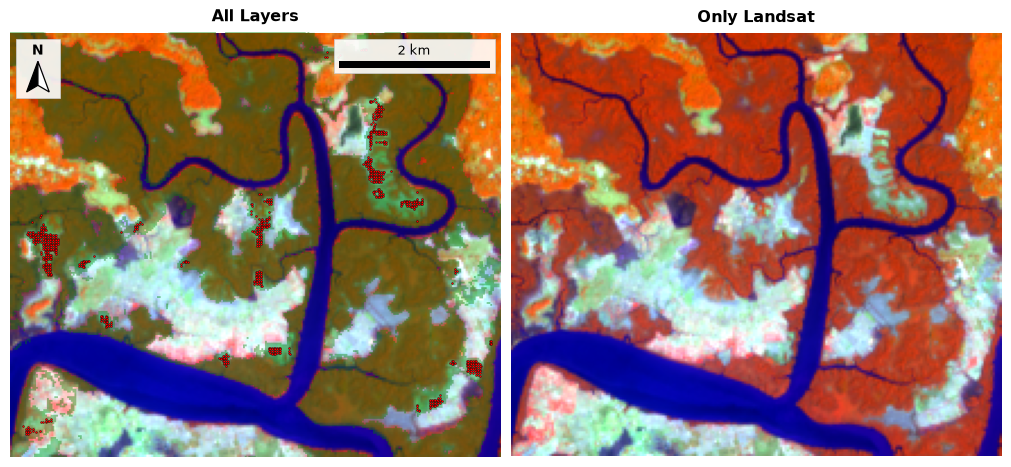

In [9]:
bbox = [460000, 466500, 1245102, 1250726]

# The first panel draws the GMW extent and the alerts over the Landsat
# image (base_img); the second panel shows only the Landsat image.
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "vector",
            vec=[gmw_2018_ext_utm_gdf, gmw_alerts_gdf],
            base_img=landsat_img,
            base_bands=[5, 6, 4],
            title="All Layers",
            map_kw={
                "vec_fill_clrs": ["green", "red"],
                "vec_line_widths": [0, 0.25],
                "vec_fill_alphas": [0.4, 1.0],  # make GMW extent transparent
                "vec_markersize": 2,
            },
        ),
        map_layout.MapPanel("rgb", landsat_img, bands=[5, 6, 4], title="Only Landsat"),
    ],
    bbox=bbox,
)

## Create Choropleth Map

Colouring the features by an attribute is an important aspect of creating a map, the `rsgispy.mapping.vector.create_choropleth_vec_lyr_map` function can be used to do that. 

In [10]:
# Use the head function to add the column headings and first few rows:
gmw_alerts_gdf.head()

,fid,score,firstobsyear,firstobsmonth,firstobsday,first_obs_date,scr5obsyear,scr5obsmonth,scr5obsday,scr5_obs_date,...,rm_qa,lastobsyear,lastobsmonth,lastobsday,last_obs_date,confident,created_at,uid,id,geometry
0,564,5,2019,1,31,2019-01-31,2019,1,31,2019-01-31,...,False,2019,1,31,2019-01-31,5,2023-02-10 07:51:36,564,564,POINT (464173.198 1250398.392)
1,565,5,2019,1,31,2019-01-31,2019,1,31,2019-01-31,...,False,2019,1,31,2019-01-31,5,2023-02-10 07:51:36,565,565,POINT (464195.024 1250398.368)
2,567,5,2019,1,31,2019-01-31,2019,1,31,2019-01-31,...,False,2019,1,31,2019-01-31,5,2023-02-10 07:51:36,567,567,POINT (462271.104 1247658.335)
3,568,5,2019,1,31,2019-01-31,2019,1,31,2019-01-31,...,False,2019,1,31,2019-01-31,5,2023-02-10 07:51:36,568,568,POINT (462271.078 1247636.22)
4,569,5,2019,1,31,2019-01-31,2019,1,31,2019-01-31,...,False,2019,1,31,2019-01-31,5,2023-02-10 07:51:36,569,569,POINT (460172.964 1245515.731)


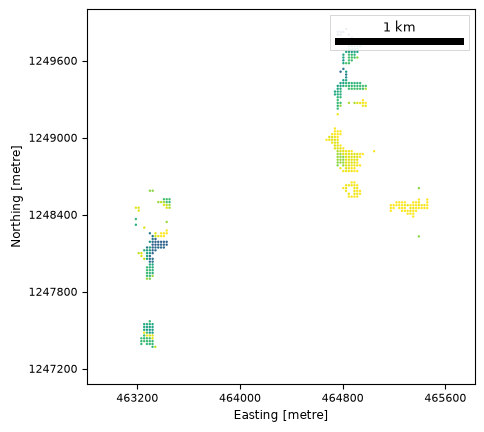

In [11]:
bbox = [462810, 465829, 1247083, 1250000]

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_date",
    bbox=bbox,
    vec_markersize=3,
    vec_line_width=0,
)

This uses the default colour bar, lets specify our own. 

### Use our own colour bar

2019-01-31 00:00:00 -- 2022-05-31 00:00:00


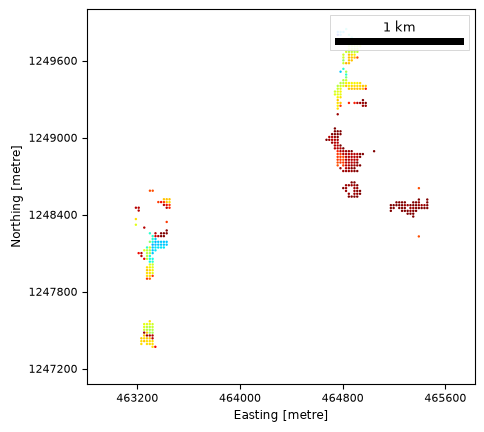

In [12]:
bbox = [462810, 465829, 1247083, 1250000]

# Create a plot using the matplotlib library
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

min_val = gmw_alerts_gdf["first_obs_date"].min()
max_val = gmw_alerts_gdf["first_obs_date"].max()

print(f"{min_val} -- {max_val}")

# Get the 'jet' colour map from matplotlib
vec_fill_cmap = matplotlib.colormaps["jet"]
vec_var_norm = None

_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_date",
    bbox=bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=3,
    vec_line_width=0,
)

### Add a colour bar to figure

It is important to tell the user of the map what the colours relate to, we therefore need to add a colour bar.

To draw a colour bar we need the colour map and the range of values the colours represent: the collection that `create_choropleth_vec_lyr_map` returns has both, so it can be passed to `fig.colorbar` (the function can also draw a colour bar itself with `show_colour_bar=True` and `cbar_label`). The range is defined by a `matplotlib.colors.Normalize` object (`vec_var_norm`); giving the same one to several maps makes their colours match, which we will use below. The alert dates are dates rather than numbers, so to make a colour bar labelled with years it is easiest to colour the alerts by a numeric column: the decimal year of the first observation (e.g., 1 July 2020 is about 2020.5). We will add this column to the GeoDataFrame and colour the alerts by it.

2019.08 -- 2022.41


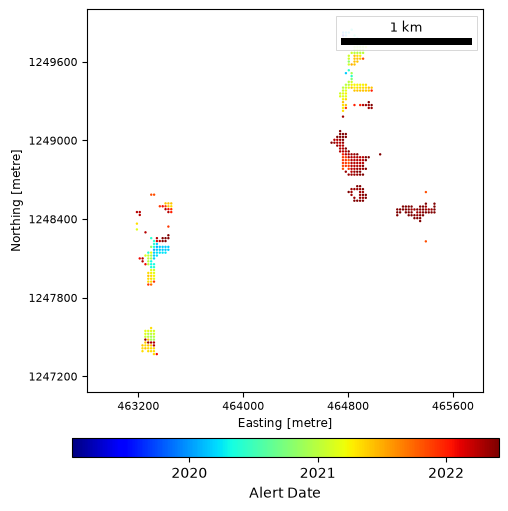

In [13]:
# Add a decimal year column for the first observation date
first_obs = gmw_alerts_gdf["first_obs_date"]
gmw_alerts_gdf["first_obs_dyear"] = first_obs.dt.year + (first_obs.dt.day_of_year - 1) / 365.25

min_val = gmw_alerts_gdf["first_obs_dyear"].min()
max_val = gmw_alerts_gdf["first_obs_dyear"].max()
print(f"{min_val:.2f} -- {max_val:.2f}")

vec_fill_cmap = matplotlib.colormaps["jet"]
vec_var_norm = matplotlib.colors.Normalize(vmin=min_val, vmax=max_val)

fig = plt.figure(figsize=(5, 5), constrained_layout=True)  #
gspec = gridspec.GridSpec(
    ncols=1, nrows=2, height_ratios=[1, 0.05], width_ratios=[1], figure=fig
)

ax01 = fig.add_subplot(gspec[0, 0])

alerts_coll = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax01,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=3,
    vec_line_width=0,
)

cbax = fig.add_subplot(gspec[1, 0])
cbar = fig.colorbar(
    mappable=alerts_coll,  # the alerts drawn on the map
    cax=cbax,
    orientation="horizontal",
    ticklocation="bottom",
    label="Alert Date",
)
# Put a tick at the start of each year
cbar.set_ticks([2020, 2021, 2022], labels=["2020", "2021", "2022"])

## Redo Our Map

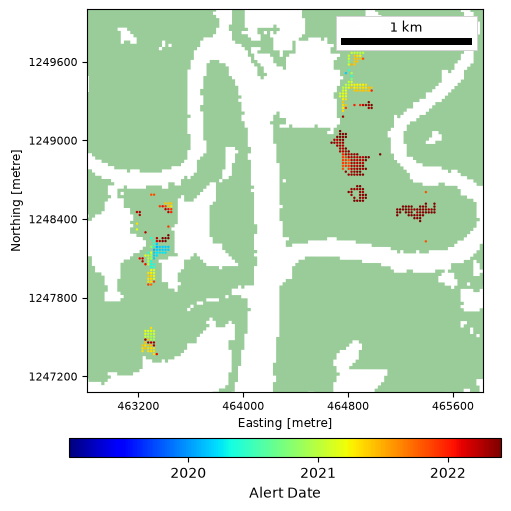

In [14]:
fig = plt.figure(figsize=(5, 5), constrained_layout=True)  #
gspec = gridspec.GridSpec(
    ncols=1, nrows=2, height_ratios=[1, 0.05], width_ratios=[1], figure=fig
)

ax01 = fig.add_subplot(gspec[0, 0])

_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax01,
    gmw_2018_ext_utm_gdf,
    bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)

alerts_coll = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax01,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=3,
    vec_line_width=0,
)

cbax = fig.add_subplot(gspec[1, 0])
cbar = fig.colorbar(
    mappable=alerts_coll,  # the alerts drawn on the map
    cax=cbax,
    orientation="horizontal",
    ticklocation="bottom",
    label="Alert Date",
)
cbar.set_ticks([2020, 2021, 2022], labels=["2020", "2021", "2022"])
plt.savefig(os.path.join(out_dir, "gmw_alerts_example.png"))

## Now try a fancy example...

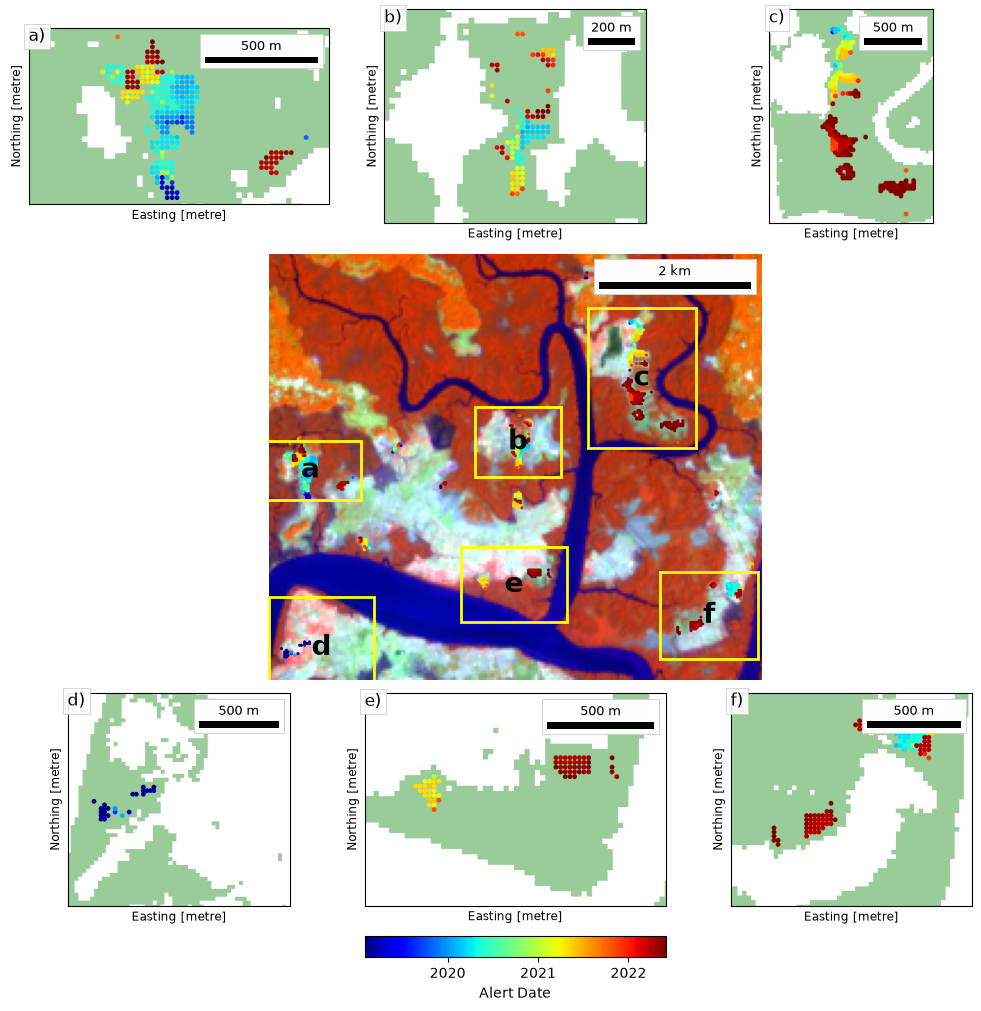

In [15]:
fig = plt.figure(figsize=(10, 10), constrained_layout=True)  #
gspec = gridspec.GridSpec(
    ncols=3,
    nrows=4,
    height_ratios=[0.5, 1, 0.5, 0.05],
    width_ratios=[1, 1, 1],
    figure=fig,
)
gspec.update(wspace=0.05, hspace=0.05)  # set the spacing between axes.

# Use the colour map and normalisation defined above

###################################################
# Start ROW 1
###################################################
ax_00 = fig.add_subplot(gspec[0, 0])
sub1_bbox = [459893, 461217, 1247476, 1248253]
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax_00,
    gmw_2018_ext_utm_gdf,
    bbox=sub1_bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_00,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=sub1_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=12,
    vec_line_width=0,
)
ax_00.set_xticks([])
ax_00.set_yticks([])
_ = rsgispy.mapping.elements.add_axis_label(ax_00, "a)")
###################################################

###################################################
ax_01 = fig.add_subplot(gspec[0, 1])
sub2_bbox = [462726, 463849, 1247776, 1248692]
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax_01,
    gmw_2018_ext_utm_gdf,
    bbox=sub2_bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_01,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=sub2_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=12,
    vec_line_width=0,
)
ax_01.set_xticks([])
ax_01.set_yticks([])
_ = rsgispy.mapping.elements.add_axis_label(ax_01, "b)")
###################################################

###################################################
ax_02 = fig.add_subplot(gspec[0, 2])
sub3_bbox = [464210, 465630, 1248153, 1249996]
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax_02,
    gmw_2018_ext_utm_gdf,
    bbox=sub3_bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_02,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=sub3_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=12,
    vec_line_width=0,
)
ax_02.set_xticks([])
ax_02.set_yticks([])
_ = rsgispy.mapping.elements.add_axis_label(ax_02, "c)")
###################################################
# End ROW 1
###################################################


# ROW 2: Landsat


###################################################
# Start ROW 3
###################################################
ax_20 = fig.add_subplot(gspec[2, 0])
sub4_bbox = [460009, 461391, 1244866, 1246190]
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax_20,
    gmw_2018_ext_utm_gdf,
    bbox=sub4_bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_20,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=sub4_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=12,
    vec_line_width=0,
)
ax_20.set_xticks([])
ax_20.set_yticks([])
_ = rsgispy.mapping.elements.add_axis_label(ax_20, "d)")
###################################################

###################################################
ax_21 = fig.add_subplot(gspec[2, 1])
sub5_bbox = [462535, 463938, 1245861, 1246853]
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax_21,
    gmw_2018_ext_utm_gdf,
    bbox=sub5_bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_21,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=sub5_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=12,
    vec_line_width=0,
)
ax_21.set_xticks([])
ax_21.set_yticks([])
_ = rsgispy.mapping.elements.add_axis_label(ax_21, "e)")
###################################################

###################################################
ax_22 = fig.add_subplot(gspec[2, 2])
sub6_bbox = [465158, 466451, 1245378, 1246523]
_ = rsgispy.mapping.vector.create_vec_lyr_map(
    ax_22,
    gmw_2018_ext_utm_gdf,
    bbox=sub6_bbox,
    vec_fill_clrs="green",
    vec_line_widths=0,
    vec_fill_alphas=0.4,  # make GMW extent transparent
)
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_22,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=sub6_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=12,
    vec_line_width=0,
)
ax_22.set_xticks([])
ax_22.set_yticks([])
_ = rsgispy.mapping.elements.add_axis_label(ax_22, "f)")
###################################################
# End ROW 2
###################################################

###################################################
ax_1 = fig.add_subplot(gspec[1, :])
ls_bbox = [460000, 466500, 1245102, 1250726]
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax_1,
    landsat_img,
    img_bands=[5, 6, 4],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    bbox=ls_bbox,
)
alerts_coll = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax_1,
    gp_vec=gmw_alerts_gdf,
    vec_col="first_obs_dyear",
    bbox=ls_bbox,
    vec_fill_cmap=vec_fill_cmap,
    vec_var_norm=vec_var_norm,
    vec_markersize=5,
    vec_line_width=0,
    show_map_axis=False,
)
_ = rsgispy.mapping.elements.draw_bboxes_to_axis(
    ax_1,
    bboxes=[sub1_bbox, sub2_bbox, sub3_bbox, sub4_bbox, sub5_bbox, sub6_bbox],
    bbox_labels=["a", "b", "c", "d", "e", "f"],
    rect_clr="yellow",
    line_width=2,
    lbl_font_size=20,
    lbl_font_weight="bold",
)
###################################################


###################################################
cbax = fig.add_subplot(gspec[3, 1])
cbar = fig.colorbar(
    mappable=alerts_coll,  # all the maps use the same colour map and norm
    cax=cbax,
    orientation="horizontal",
    ticklocation="bottom",
    label="Alert Date",
)
cbar.set_ticks([2020, 2021, 2022], labels=["2020", "2021", "2022"])
###################################################

plt.savefig(os.path.join(out_dir, "gmw_alerts_fancy_example.png"), dpi=400)